## 0. Configuração do Ambiente e Diretório de Trabalho (Google Drive)

Para garantir a persistência dos arquivos intermediários (`data/processed/`) e dos entregáveis (`outputs/`) entre todos os notebooks do pipeline (`01` a `06`) sem necessidade de reenvio manual a cada sessão do Google Colab, montamos o Google Drive e definimos a pasta raiz do projeto (`ifood-growth-competition-case`) como diretório ativo.

> **Nota de reprodutibilidade:** Caso execute este notebook localmente (VS Code / Jupyter), esta célula identifica automaticamente o ambiente local e mantém o diretório raiz do repositório sem exigir montagem do Google Drive.

In [7]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/ifood-growth-competition-case'
    os.makedirs(PROJECT_DIR, exist_ok=True)
    os.chdir(PROJECT_DIR)
    print("Ambiente Google Colab conectado ao Drive:", os.getcwd())
except ImportError:
    # Execução local (VS Code / Jupyter / Terminal)
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    print("Ambiente local detectado:", os.getcwd())

Mounted at /content/drive
Ambiente Google Colab conectado ao Drive: /content/drive/MyDrive/ifood-growth-competition-case


# 03 — Modelagem de Impacto por Alavanca (Ancorada nos Custos Reais da Base)

**Objetivo:** Simular o impacto econômico e operacional de cada alavanca por cidade utilizando diretamente as variáveis reais da base:
- **`Custo/Pedido incremental`** (`custo_pedido_incremental`, em R$/pedido) para alavancas de demanda (*Incentivos para Clientes* e *Frete Grátis*).
- **`Custo/Hora Incremental`** (`custo_hora_incremental`, em R$/hora) e base de **`Entregadores`** para a alavanca de oferta (*Incentivos para Entregadores / Capacidade*).
- **`Price Index`** (`price_index_pct`) e **`Margem de Contribuição`** (`margem_contribuicao_pct`) para calibrar *Alterações de Preço* e o ganho marginal real por pedido.

**Regras de governança:**
1. **Praças saturadas (`saturacao_pct > 100%`)** só podem receber **Incentivos para Entregadores** (para reduzir saturação logística), sendo bloqueadas para alavancas de estímulo bruto de demanda.
2. **Canibalização (`15%`)** é aplicada **uma única vez** no volume incremental líquido.
3. **Respeito ao limite obrigatório de -R$ 10M na Operating Margin**: cada ação registra tanto o **custo direto da alavanca (`custo_alavanca_m`)** quanto o **impacto líquido na Operating Margin (`operating_margin_incremental_m`)**.


In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = ".." if os.path.exists("../data/processed/base_segmentada.csv") else ("." if os.path.exists("data/processed/base_segmentada.csv") else "/content")
SEGMENTED_PATH = os.path.join(BASE_DIR, "data", "processed", "base_segmentada.csv")
IMPACT_PATH = os.path.join(BASE_DIR, "data", "processed", "base_impacto.csv")
FIGURES_DIR = os.path.join(BASE_DIR, "outputs", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

df = pd.read_csv(SEGMENTED_PATH)

PREMISSAS = {
    "elasticidade_demanda": 1.4,
    "canibalizacao": 0.15,
    "uplift_base_incentivo_cliente": 0.075,
    "uplift_base_frete_gratis": 0.095,
    "uplift_base_preco": 0.060,
    "diluicao_preco_pct_gmv": 0.012,
    "horas_extras_por_entregador_ano": 180.0,   # ~15h/mês por entregador ativo
    "reducao_saturacao_pp_capacidade": 12.0,    # alívio de saturação com reforço de frota/turno
    "uplift_desbloqueio_capacidade": 0.045,     # pedidos recuperados por menor tempo de espera/cancelamento
    "saturacao_max_pos_demanda": 100.0
}

print("Premissas carregadas:", PREMISSAS)


Premissas carregadas: {'elasticidade_demanda': 1.4, 'canibalizacao': 0.15, 'uplift_base_incentivo_cliente': 0.075, 'uplift_base_frete_gratis': 0.095, 'uplift_base_preco': 0.06, 'diluicao_preco_pct_gmv': 0.012, 'horas_extras_por_entregador_ano': 180.0, 'reducao_saturacao_pp_capacidade': 12.0, 'uplift_desbloqueio_capacidade': 0.045, 'saturacao_max_pos_demanda': 100.0}


## 1. Simulação Econômica e Operacional por Cidade e Alavanca


In [9]:
def estimate_lever_impact(row, lever):
    gmv = float(row["gmv_base_m"])
    orders_k = float(row["pedidos_base_k"])
    sat_base = float(row["saturacao_pct"])
    margem_contrib_pct = float(row["margem_contribuicao_pct"])
    custo_pedido_real = float(row["custo_pedido_incremental"])
    custo_hora_real = float(row["custo_hora_incremental"])
    entregadores = float(row["entregadores"])
    price_index = float(row["price_index_pct"])
    frete_gratis_atual = float(row["frete_gratis_pct"])

    elegivel_demanda = bool(row["elegivel_demanda"])
    elegivel_capacidade = bool(row["elegivel_capacidade"])

    cannib = PREMISSAS["canibalizacao"]
    elast_factor = PREMISSAS["elasticidade_demanda"] / 1.4

    # 1. Alavancas de Demanda (bloqueadas se não elegível a demanda ou se saturação > 100%)
    if lever in ["Incentivos para Clientes", "Frete Grátis", "Alterações de Preço"]:
        if not elegivel_demanda or sat_base > 100.0:
            return pd.Series({
                "alavanca": lever,
                "viavel_operacionalmente": False,
                "motivo_bloqueio": f"Bloqueado para demanda ({row['arquetipo_operacional']})",
                "custo_alavanca_m": 0.0,
                "pedidos_incrementais_k": 0.0,
                "gmv_incremental_m": 0.0,
                "margem_contribuicao_incremental_m": 0.0,
                "operating_margin_incremental_m": 0.0,
                "saturacao_pos_pct": sat_base,
                "roi_gmv": 0.0,
                "roi_margem": 0.0
            })

        if lever == "Incentivos para Clientes":
            uplift_liq = PREMISSAS["uplift_base_incentivo_cliente"] * elast_factor * (1.0 - cannib)
            inc_orders_k = orders_k * uplift_liq
            inc_gmv_m = gmv * uplift_liq
            # Usa o Custo/Pedido incremental real da cidade
            custo_alavanca_m = (inc_orders_k * 1_000.0 * custo_pedido_real) / 1_000_000.0
            delta_sat = uplift_liq * 100.0 * 0.65

        elif lever == "Frete Grátis":
            # Menor eficiência marginal se a praça já possui penetração muito alta de frete grátis (> 50%)
            fator_fg = 0.80 if frete_gratis_atual > 50.0 else 1.05
            uplift_liq = PREMISSAS["uplift_base_frete_gratis"] * elast_factor * fator_fg * (1.0 - cannib)
            inc_orders_k = orders_k * uplift_liq
            inc_gmv_m = gmv * uplift_liq
            # Frete grátis custa ~1.25x o custo/pedido incremental padrão da cidade
            custo_alavanca_m = (inc_orders_k * 1_000.0 * (custo_pedido_real * 1.25)) / 1_000_000.0
            delta_sat = uplift_liq * 100.0 * 0.70

        elif lever == "Alterações de Preço":
            # Mais eficaz onde o Price Index está acima de 100% (preço menos competitivo)
            fator_preco = 1.20 if price_index > 100.0 else 0.75
            uplift_liq = PREMISSAS["uplift_base_preco"] * elast_factor * fator_preco * (1.0 - cannib)
            inc_orders_k = orders_k * uplift_liq
            inc_gmv_m = gmv * uplift_liq
            custo_alavanca_m = (gmv + inc_gmv_m) * PREMISSAS["diluicao_preco_pct_gmv"]
            delta_sat = uplift_liq * 100.0 * 0.60

        sat_pos = sat_base + delta_sat
        if sat_pos > PREMISSAS["saturacao_max_pos_demanda"]:
            return pd.Series({
                "alavanca": lever,
                "viavel_operacionalmente": False,
                "motivo_bloqueio": f"Estoura saturação máxima ({sat_pos:.1f}% > 100%)",
                "custo_alavanca_m": round(custo_alavanca_m, 4),
                "pedidos_incrementais_k": round(inc_orders_k, 4),
                "gmv_incremental_m": round(inc_gmv_m, 4),
                "margem_contribuicao_incremental_m": 0.0,
                "operating_margin_incremental_m": 0.0,
                "saturacao_pos_pct": round(sat_pos, 2),
                "roi_gmv": 0.0,
                "roi_margem": 0.0
            })

    # 2. Alavanca de Capacidade / Oferta: Incentivos para Entregadores
    elif lever == "Incentivos para Entregadores":
        if not elegivel_capacidade:
            return pd.Series({
                "alavanca": lever,
                "viavel_operacionalmente": False,
                "motivo_bloqueio": "Praça sem gargalo crítico de saturação",
                "custo_alavanca_m": 0.0,
                "pedidos_incrementais_k": 0.0,
                "gmv_incremental_m": 0.0,
                "margem_contribuicao_incremental_m": 0.0,
                "operating_margin_incremental_m": 0.0,
                "saturacao_pos_pct": sat_base,
                "roi_gmv": 0.0,
                "roi_margem": 0.0
            })

        # Usa Custo/Hora Incremental real da cidade e frota ativa
        custo_alavanca_m = (entregadores * PREMISSAS["horas_extras_por_entregador_ano"] * custo_hora_real) / 1_000_000.0
        # Destrava pedidos represados pela saturação sem gerar canibalização
        uplift_liq = PREMISSAS["uplift_desbloqueio_capacidade"] * (1.0 - cannib)
        inc_orders_k = orders_k * uplift_liq
        inc_gmv_m = gmv * uplift_liq
        sat_pos = max(sat_base - PREMISSAS["reducao_saturacao_pp_capacidade"], 70.0)

    else:
        raise ValueError(f"Alavanca inválida: {lever}")

    # Margem de contribuição incremental gerada pelo novo GMV (usando Margem de Contribuição real da praça)
    mc_inc_m = inc_gmv_m * (margem_contrib_pct / 100.0)
    op_margin_inc_m = mc_inc_m - custo_alavanca_m

    roi_gmv = (inc_gmv_m / custo_alavanca_m) if custo_alavanca_m > 0 else 0.0
    roi_margem = (op_margin_inc_m / custo_alavanca_m) if custo_alavanca_m > 0 else 0.0

    return pd.Series({
        "alavanca": lever,
        "viavel_operacionalmente": True,
        "motivo_bloqueio": "OK",
        "custo_alavanca_m": round(custo_alavanca_m, 4),
        "pedidos_incrementais_k": round(inc_orders_k, 4),
        "gmv_incremental_m": round(inc_gmv_m, 4),
        "margem_contribuicao_incremental_m": round(mc_inc_m, 4),
        "operating_margin_incremental_m": round(op_margin_inc_m, 4),
        "saturacao_pos_pct": round(sat_pos, 2),
        "roi_gmv": round(roi_gmv, 2),
        "roi_margem": round(roi_margem, 2)
    })


## 2. Execução da Simulação para Todas as Cidades e Alavancas


In [10]:
levers = [
    "Incentivos para Clientes",
    "Frete Grátis",
    "Alterações de Preço",
    "Incentivos para Entregadores"
]

impact_rows = []
for _, row in df.iterrows():
    for lever in levers:
        res = estimate_lever_impact(row, lever)
        res["cidade"] = row["cidade"]
        res["arquetipo_operacional"] = row["arquetipo_operacional"]
        res["gmv_base_m"] = row["gmv_base_m"]
        res["saturacao_base_pct"] = row["saturacao_pct"]
        res["margem_base_pct"] = row["margem_base_pct"]
        res["margem_contribuicao_pct"] = row["margem_contribuicao_pct"]
        impact_rows.append(res)

impact_df = pd.DataFrame(impact_rows)

viaveis = impact_df[impact_df["viavel_operacionalmente"]].sort_values("roi_gmv", ascending=False)
print("Total de simulações:", len(impact_df))
print("Combinações operacionalmente viáveis:", len(viaveis))
display(viaveis[[
    "cidade", "arquetipo_operacional", "alavanca", "custo_alavanca_m",
    "pedidos_incrementais_k", "gmv_incremental_m",
    "margem_contribuicao_incremental_m", "operating_margin_incremental_m",
    "saturacao_base_pct", "saturacao_pos_pct", "roi_gmv", "roi_margem"
]])


Total de simulações: 80
Combinações operacionalmente viáveis: 14


,cidade,arquetipo_operacional,alavanca,custo_alavanca_m,pedidos_incrementais_k,gmv_incremental_m,margem_contribuicao_incremental_m,operating_margin_incremental_m,saturacao_base_pct,saturacao_pos_pct,roi_gmv,roi_margem
44,City 2,Ataque Competitivo,Incentivos para Clientes,0.3869,77.3722,5.5956,0.5014,0.1145,83.86,88.00,14.46,0.30
45,City 2,Ataque Competitivo,Frete Grátis,0.4900,78.4038,5.6702,0.5080,0.0180,83.86,88.38,11.57,0.04
52,City 3,Ataque Competitivo,Incentivos para Clientes,0.5885,84.0762,6.4520,0.5304,-0.0582,79.81,83.95,10.96,-0.10
36,City 18,Turnaround Estrutural,Incentivos para Clientes,0.2815,40.2075,2.6722,0.2063,-0.0752,78.48,82.62,9.49,-0.27
53,City 3,Ataque Competitivo,Frete Grátis,0.9784,111.8213,8.5812,0.7054,-0.2731,79.81,85.75,8.77,-0.28
37,City 18,Turnaround Estrutural,Frete Grátis,0.3565,40.7436,2.7078,0.2090,-0.1475,78.48,83.00,7.60,-0.41
46,City 2,Ataque Competitivo,Alterações de Preço,1.1177,74.2773,5.3717,0.4813,-0.6364,83.86,87.53,4.81,-0.57
54,City 3,Ataque Competitivo,Alterações de Preço,1.2888,80.7131,6.1939,0.5091,-0.7797,79.81,83.48,4.81,-0.60
38,City 18,Turnaround Estrutural,Alterações de Preço,0.5222,24.1245,1.6033,0.1238,-0.3985,78.48,80.78,3.07,-0.76
59,City 4,Destravamento de Capacidade (Saturada),Incentivos para Entregadores,1.1871,30.3458,1.9952,0.1552,-1.0319,129.05,117.05,1.68,-0.87


## 3. Visualização das Oportunidades Viáveis por Alavanca


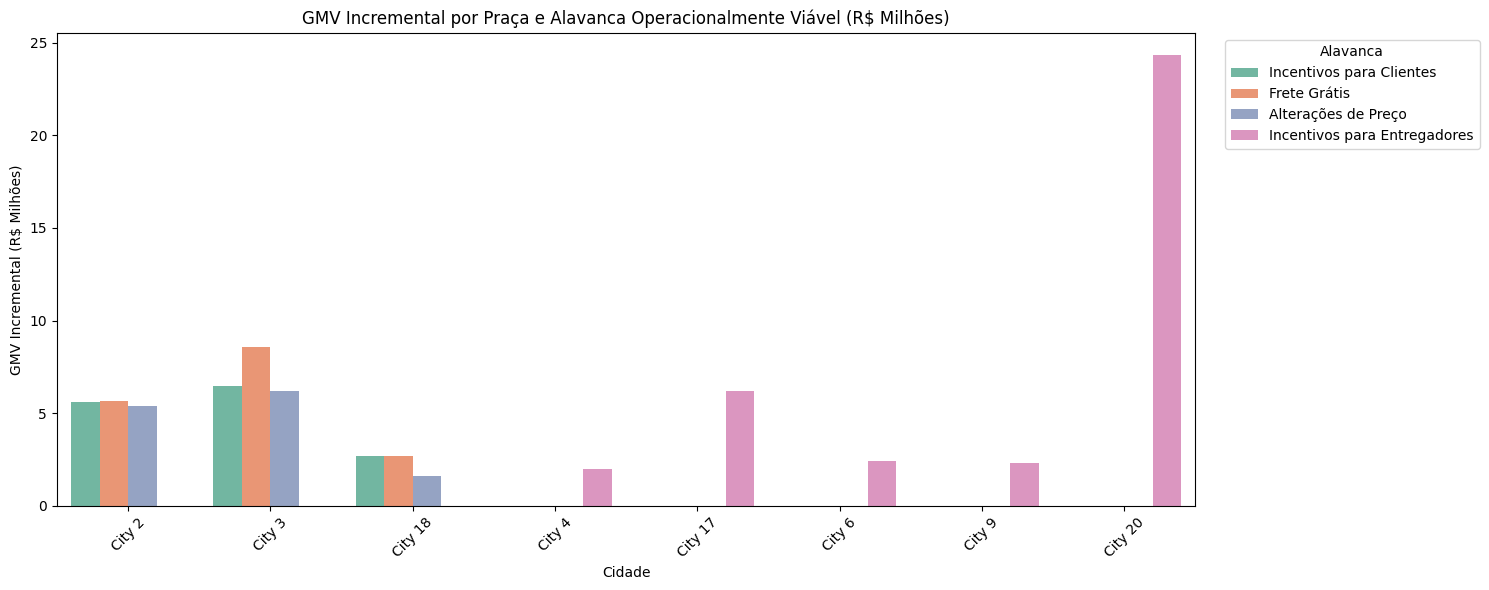

In [11]:
if not viaveis.empty:
    plt.figure(figsize=(15, 6))
    sns.barplot(
        data=viaveis,
        x="cidade",
        y="gmv_incremental_m",
        hue="alavanca",
        palette="Set2"
    )
    plt.title("GMV Incremental por Praça e Alavanca Operacionalmente Viável (R$ Milhões)")
    plt.xlabel("Cidade")
    plt.ylabel("GMV Incremental (R$ Milhões)")
    plt.xticks(rotation=45)
    plt.legend(title="Alavanca", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, "03_oportunidades_por_alavanca.png"), bbox_inches="tight", dpi=150)
    plt.show()


## 4. Exportação da Base de Impacto


In [12]:
impact_df.to_csv(IMPACT_PATH, index=False)
print("Base de impacto salva em:", IMPACT_PATH)


Base de impacto salva em: ./data/processed/base_impacto.csv
